In [4]:
import pandas as pd
df = pd.read_parquet("data/processed/annunci_flat.parquet")
df.shape

(15576, 37)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15576 entries, 0 to 15575
Data columns (total 37 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   price_raw         15313 non-null  float64
 1   surface_m2        15568 non-null  float64
 2   rooms             15514 non-null  float64
 3   bathrooms         15314 non-null  float64
 4   bedrooms          14990 non-null  float64
 5   floor_raw         15129 non-null  str    
 6   lift              15033 non-null  float64
 7   is_luxury         15576 non-null  int64  
 8   has_cellar        15576 non-null  int64  
 9   has_balcony       15576 non-null  int64  
 10  has_terrace       15576 non-null  int64  
 11  furnished         15576 non-null  int64  
 12  macrozone_id      15575 non-null  float64
 13  macrozone_name    15575 non-null  str    
 14  microzone_id      15540 non-null  float64
 15  microzone_name    15540 non-null  str    
 16  zone_id           10176 non-null  float64
 17  zone

In [6]:
df.describe()


,price_raw,surface_m2,rooms,bathrooms,bedrooms,lift,is_luxury,has_cellar,has_balcony,has_terrace,...,condo_fees_month,id,creation_date,last_modified,is_project,crawled_at,has_parking,armored_door,fiber,alarm
count,1.531300e+04,15568.000000,15514.000000,15314.000000,14990.000000,15033.000000,15576.000000,15576.000000,15576.000000,15576.000000,...,12662.000000,1.557600e+04,1.557600e+04,1.557600e+04,15576.000000,1.557600e+04,15576.0,15576.000000,15576.00000,15576.000000
mean,5.806560e+05,117.300039,2.798376,1.435745,1.960307,0.789064,0.232922,0.562275,0.568246,0.220082,...,314.903175,1.275894e+08,1.771023e+09,1.780285e+09,0.009117,1.784549e+09,0.0,0.783320,0.68047,0.195108
std,6.970007e+05,534.653230,1.049455,0.635549,16.114527,0.407987,0.422707,0.496123,0.495336,0.414315,...,4418.992418,5.165815e+06,2.123512e+07,7.218797e+06,0.095048,6.984576e-01,0.0,0.411996,0.46631,0.396296
min,2.024000e+04,7.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,4.560968e+07,1.395144e+09,1.646174e+09,0.000000,1.784549e+09,0.0,0.000000,0.00000,0.000000
25%,2.690000e+05,58.000000,2.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,120.000000,1.270671e+08,1.770037e+09,1.779707e+09,0.000000,1.784549e+09,0.0,1.000000,0.00000,0.000000
50%,3.890000e+05,80.000000,3.000000,1.000000,2.000000,1.000000,0.000000,1.000000,1.000000,0.000000,...,180.000000,1.290837e+08,1.777057e+09,1.782484e+09,0.000000,1.784549e+09,0.0,1.000000,1.00000,0.000000
75%,6.300000e+05,115.000000,3.000000,2.000000,2.000000,1.000000,0.000000,1.000000,1.000000,0.000000,...,260.000000,1.301667e+08,1.781256e+09,1.783934e+09,0.000000,1.784549e+09,0.0,1.000000,1.00000,0.000000
max,1.800000e+07,27551.000000,5.000000,3.000000,1970.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,375000.000000,1.311091e+08,1.784461e+09,1.784500e+09,1.000000,1.784549e+09,0.0,1.000000,1.00000,1.000000


In [ ]:
df[["price_raw", "surface_m2", "rooms", "microzone_name", "condition", "year_built"]].head(20)

In [8]:
import json
with open("data/raw/annunci_milano.checkpoint.jsonl") as f:
    for i, line in enumerate(f):
        tags = json.loads(line).get("featuresTags")
        if tags:
            print(tags)
        if i > 8:
            break

['Infissi esterni in doppio vetro / PVC', 'Parcheggio bici']
['Infissi esterni in doppio vetro / PVC', 'Parcheggio bici']
['Esposizione interna', 'Fibra ottica', 'Infissi esterni in triplo vetro / PVC', 'Porta blindata']
['Infissi esterni in vetro / PVC', 'Parcheggio bici']
['Esposizione doppia', 'Fibra ottica', 'Impianto tv centralizzato', 'Infissi esterni in doppio vetro / metallo', 'Mansarda', 'Porta blindata', 'VideoCitofono']
['Armadio a muro', 'Caminetto', 'Esposizione doppia', 'Fibra ottica', 'Impianto di allarme', 'Impianto tv centralizzato', 'Infissi esterni in vetro / PVC', 'Porta blindata', 'Taverna']
['Esposizione doppia', 'Fibra ottica', 'Impianto tv centralizzato', 'Infissi esterni in doppio vetro / legno', 'Porta blindata']
['Infissi esterni in doppio vetro / PVC', 'Parcheggio bici']
['Infissi esterni in doppio vetro / metallo', 'Parcheggio bici']
['Armadio a muro', 'Cancello elettrico', 'Esposizione doppia', 'Fibra ottica', 'Impianto tv centralizzato', 'Infissi esterni 

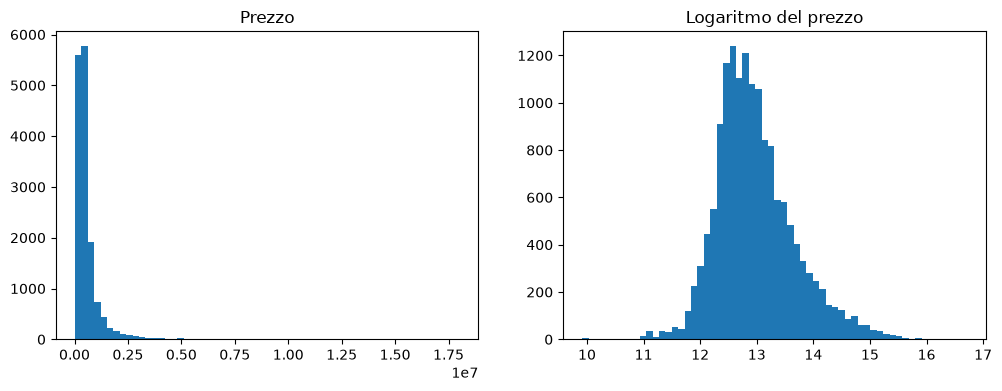

In [9]:
import matplotlib.pyplot as plt
import numpy as np

fig, assi = plt.subplots(1, 2, figsize=(12, 4))
assi[0].hist(df["price_raw"].dropna(), bins=60)
assi[0].set_title("Prezzo")
assi[1].hist(np.log1p(df["price_raw"].dropna()), bins=60)
assi[1].set_title("Logaritmo del prezzo")
plt.show()

In [10]:
import json
with open("data/raw/annunci_milano.checkpoint.jsonl") as f:
    for i, line in enumerate(f):
        topo = json.loads(line).get("topology", {})
        print(sorted(topo.keys()))
        if i > 4:
            break

['bathrooms', 'category', 'floor', 'isLuxury', 'lift', 'rooms', 'surface', 'typology']
['bathrooms', 'category', 'floor', 'isLuxury', 'lift', 'rooms', 'surface', 'typology']
['bathrooms', 'category', 'cellar', 'floor', 'isLuxury', 'lift', 'rooms', 'surface', 'typology']
['bathrooms', 'category', 'floor', 'isLuxury', 'lift', 'rooms', 'surface', 'typology']
['balcony', 'bathrooms', 'category', 'cellar', 'floor', 'isLuxury', 'lift', 'rooms', 'surface', 'typology']
['bathrooms', 'category', 'cellar', 'floor', 'furnished', 'isLuxury', 'lift', 'rooms', 'surface', 'typology']


In [11]:
import json
aste = 0
progetti = 0
with open("data/raw/annunci_milano.checkpoint.jsonl") as f:
    for line in f:
        rec = json.loads(line)
        if rec.get("auctionsDetails"):
            aste += 1
        if (rec.get("subProperties") or {}).get("count"):
            progetti += 1
print("aste:", aste, "| progetti:", progetti)

aste: 435 | progetti: 142


In [12]:
import pandas as pd
df = pd.read_parquet("data/processed/annunci_flat.parquet")
print("righe totali:", len(df))

righe totali: 15576


In [13]:
print("aste:", df["is_auction"].sum())
print("progetti:", df["is_project"].sum())
print("prezzo mancante:", df["price_raw"].isna().sum())

aste: 435
progetti: 142
prezzo mancante: 263


In [14]:
da_togliere = df["is_auction"].astype(bool) | df["is_project"].astype(bool) | df["price_raw"].isna()
print("righe da rimuovere in totale:", da_togliere.sum())
print("righe che resterebbero:", (~da_togliere).sum())

righe da rimuovere in totale: 839
righe che resterebbero: 14737


In [15]:
df_clean = df[~da_togliere].copy()
print("righe dopo la prima potatura:", len(df_clean))

righe dopo la prima potatura: 14737


In [ ]:
df_clean.nlargest(15, "surface_m2")[["price_raw", "surface_m2", "rooms", "microzone_name", "condition"]]

In [17]:
df_clean["prezzo_mq"] = df_clean["price_raw"] / df_clean["surface_m2"]
df_clean["prezzo_mq"].describe()


count    14737.000000
mean      5768.857687
std       2660.562788
min         72.500000
25%       4090.909091
50%       5187.500000
75%       6787.234043
max      76428.571429
Name: prezzo_mq, dtype: float64

In [18]:
print("sopra 1000 mq:", (df_clean["surface_m2"] > 1000).sum())

sopra 1000 mq: 24


In [19]:
fuori = (df_clean["prezzo_mq"] < 1000) | (df_clean["prezzo_mq"] > 30000)
print("fuori dalla fascia prezzo/mq:", fuori.sum())

fuori dalla fascia prezzo/mq: 14


In [ ]:
df_clean.nsmallest(10, "prezzo_mq")[["price_raw", "surface_m2", "microzone_name", "condition"]]

In [ ]:
df_clean.nlargest(10, "prezzo_mq")[["price_raw", "surface_m2", "microzone_name", "condition"]]

In [22]:
soglia_mq = 1000
soglia_prezzo_mq_min = 1000
soglia_prezzo_mq_max = 30000

outlier = (
    (df_clean["surface_m2"] > soglia_mq)
    | (df_clean["prezzo_mq"] < soglia_prezzo_mq_min)
    | (df_clean["prezzo_mq"] > soglia_prezzo_mq_max)
)
print("outlier totali da togliere:", outlier.sum())
print("righe che resterebbero:", (~outlier).sum())

outlier totali da togliere: 32
righe che resterebbero: 14705


In [23]:
for soglia in [30000, 20000, 15000, 12000]:
    n = (df_clean["prezzo_mq"] > soglia).sum()
    print(f"sopra {soglia} euro/mq: {n} immobili")

sopra 30000 euro/mq: 4 immobili
sopra 20000 euro/mq: 31 immobili
sopra 15000 euro/mq: 157 immobili
sopra 12000 euro/mq: 402 immobili


In [24]:
outlier = (
    (df_clean["surface_m2"] > 1000)
    | (df_clean["prezzo_mq"] < 1000)
    | (df_clean["prezzo_mq"] > 20000)
)
print("outlier da togliere:", outlier.sum())
df_model = df_clean[~outlier].copy()
print("righe finali per il modello:", len(df_model))

outlier da togliere: 59
righe finali per il modello: 14678


In [25]:
df_model.to_parquet("data/processed/annunci_clean.parquet", index=False)
print("salvato:", len(df_model), "annunci puliti")

salvato: 14678 annunci puliti


In [26]:
import pandas as pd
df_model = pd.read_parquet("data/processed/annunci_clean.parquet")
df_model["bedrooms"].value_counts(dropna=False).sort_index()

bedrooms
0.0         15
1.0       6500
2.0       5193
3.0       1950
4.0        474
5.0        125
6.0         39
7.0         12
8.0          3
9.0          1
10.0         1
11.0         1
12.0         1
14.0         1
1970.0       1
NaN        361
Name: count, dtype: int64

In [27]:
corrotti = df_model["bedrooms"] > 10
print("bedrooms corrotti da azzerare:", corrotti.sum())

bedrooms corrotti da azzerare: 4


In [28]:
corrotti = df_model["bedrooms"] > 7
print("bedrooms corrotti da azzerare:", corrotti.sum())

bedrooms corrotti da azzerare: 9


In [29]:
import numpy as np
df_model.loc[df_model["bedrooms"] > 8, "bedrooms"] = np.nan
print("righe totali intatte:", len(df_model))
print("bedrooms ora mancanti:", df_model["bedrooms"].isna().sum())

righe totali intatte: 14678
bedrooms ora mancanti: 367


In [30]:
df_model.to_parquet("data/processed/annunci_clean.parquet", index=False)
print("risalvato con bedrooms riparata:", len(df_model), "annunci")

risalvato con bedrooms riparata: 14678 annunci


In [31]:
import pandas as pd
import numpy as np

df = pd.read_parquet("data/processed/annunci_clean.parquet")

# il bersaglio: logaritmo del prezzo
y = np.log1p(df["price_raw"])

# per la baseline partiamo dalle feature numeriche pulite e sempre presenti
feature = ["surface_m2", "rooms", "bathrooms", "lift", "is_luxury",
           "has_cellar", "has_balcony", "has_terrace"]
X = df[feature]

print("X:", X.shape, "| y:", y.shape)
print("valori mancanti per colonna:\n", X.isna().sum())

X: (14678, 8) | y: (14678,)
valori mancanti per colonna:
 surface_m2       0
rooms           36
bathrooms       77
lift           327
is_luxury        0
has_cellar       0
has_balcony      0
has_terrace      0
dtype: int64


In [32]:
from sklearn.model_selection import train_test_split

# per la baseline: righe complete sulle feature scelte
mask = X.notna().all(axis=1)
X_base = X[mask]
y_base = y[mask]
print("righe usate per la baseline:", len(X_base), "su", len(X))

X_tr, X_te, y_tr, y_te = train_test_split(
    X_base, y_base, test_size=0.2, random_state=42
)
print("addestramento:", len(X_tr), "| test:", len(X_te))

righe usate per la baseline: 14254 su 14678
addestramento: 11403 | test: 2851


In [33]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# BASELINE 1: il pavimento. Indovina sempre la media, ignora le feature.
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_tr, y_tr)
pred_dummy = dummy.predict(X_te)

# BASELINE 2: la regressione lineare. Usa le otto feature in modo lineare.
lin = LinearRegression()
lin.fit(X_tr, y_tr)
pred_lin = lin.predict(X_te)

# Le metriche sono calcolate in scala logaritmica, perche' y e' il log del prezzo
print("           MAE(log)   R2")
print(f"Dummy      {mean_absolute_error(y_te, pred_dummy):.3f}      {r2_score(y_te, pred_dummy):.3f}")
print(f"Lineare    {mean_absolute_error(y_te, pred_lin):.3f}      {r2_score(y_te, pred_lin):.3f}")

           MAE(log)   R2
Dummy      0.514      -0.000
Lineare    0.225      0.812


In [34]:
import numpy as np

# riportiamo le previsioni dalla scala logaritmica agli euro
pred_euro = np.expm1(pred_lin)
vero_euro = np.expm1(y_te)

mae_euro = np.mean(np.abs(pred_euro - vero_euro))
mape = np.mean(np.abs(pred_euro - vero_euro) / vero_euro) * 100

print(f"errore medio in euro: {mae_euro:,.0f}")
print(f"errore percentuale medio: {mape:.1f}%")

errore medio in euro: 138,107
errore percentuale medio: 23.6%


In [35]:
import numpy as np

errori_euro = np.abs(pred_euro - vero_euro)
print(f"errore medio (MAE):    {errori_euro.mean():,.0f} euro")
print(f"errore mediano:        {np.median(errori_euro):,.0f} euro")

errore medio (MAE):    138,107 euro
errore mediano:        74,510 euro


In [36]:
import pandas as pd

pesi = pd.Series(lin.coef_, index=feature).sort_values()
print(pesi)
print(f"\nintercetta: {lin.intercept_:.3f}")

has_cellar     0.001893
surface_m2     0.004004
has_balcony    0.015008
has_terrace    0.076606
bathrooms      0.106639
rooms          0.121353
lift           0.158326
is_luxury      0.662600
dtype: float64

intercetta: 11.816


In [37]:
import numpy as np

# effetto di ogni feature riscalato per la sua variabilita'
pesi_std = pd.Series(
    lin.coef_ * X_tr.std().values,
    index=feature
).sort_values()
print(pesi_std)

has_cellar     0.000936
has_balcony    0.007397
has_terrace    0.031636
lift           0.064155
bathrooms      0.065857
rooms          0.123239
surface_m2     0.240029
is_luxury      0.280674
dtype: float64


In [38]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_parquet("data/processed/annunci_clean.parquet")
y = np.log1p(df["price_raw"])

num_feat = ["surface_m2", "rooms", "bathrooms", "bedrooms", "lift",
            "is_luxury", "has_cellar", "has_balcony", "has_terrace"]
cat_feat = ["microzone_name"]
feature = num_feat + cat_feat

X = df[feature].copy()
# per i boosting i mancanti numerici vanno bene, ma la categoria la riempiamo
X["microzone_name"] = X["microzone_name"].fillna("Sconosciuta").astype("category")

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
print("feature usate:", feature)
print("addestramento:", len(X_tr), "| test:", len(X_te))

feature usate: ['surface_m2', 'rooms', 'bathrooms', 'bedrooms', 'lift', 'is_luxury', 'has_cellar', 'has_balcony', 'has_terrace', 'microzone_name']
addestramento: 11742 | test: 2936


In [39]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, r2_score

xgb = XGBRegressor(
    n_estimators=600,        # quanti alberi in fila
    learning_rate=0.05,      # quanto piccola ogni correzione
    max_depth=6,             # quanto profondo ogni albero
    subsample=0.8,           # ogni albero vede l'80% delle righe: riduce overfitting
    colsample_bytree=0.8,    # e l'80% delle colonne
    enable_categorical=True, # abilita la gestione nativa della microzona
    random_state=42,
)
xgb.fit(X_tr, y_tr)
pred_xgb = xgb.predict(X_te)

mae_log = mean_absolute_error(y_te, pred_xgb)
r2 = r2_score(y_te, pred_xgb)
print(f"XGBoost   MAE(log) {mae_log:.3f}   R2 {r2:.3f}")
print(f"(ricorda: Lineare senza zona era  MAE 0.225   R2 0.812)")

XGBoost   MAE(log) 0.139   R2 0.918
(ricorda: Lineare senza zona era  MAE 0.225   R2 0.812)


In [40]:
import numpy as np
pred_euro = np.expm1(pred_xgb)
vero_euro = np.expm1(y_te)
err = np.abs(pred_euro - vero_euro)
print(f"errore medio:   {err.mean():,.0f} euro")
print(f"errore mediano: {np.median(err):,.0f} euro")

errore medio:   89,651 euro
errore mediano: 42,141 euro


In [41]:
from sklearn.model_selection import cross_val_score, GroupKFold

# validazione a gruppi: le microzone diventano i gruppi
gruppi = X["microzone_name"].astype(str)

gkf = GroupKFold(n_splits=5)
scores = cross_val_score(
    xgb, X, y,
    groups=gruppi,
    cv=gkf,
    scoring="r2",
)
print("R2 per fold:", np.round(scores, 3))
print(f"R2 medio (validazione geografica): {scores.mean():.3f}  (+/- {scores.std():.3f})")

R2 per fold: [0.634 0.697 0.704 0.642 0.542]
R2 medio (validazione geografica): 0.644  (+/- 0.058)


In [42]:
import json
import numpy as np
from geopy.distance import geodesic

# --- centro citta': le coordinate del Duomo dal file zone ---
DUOMO = (45.4637, 9.18813)   # (lat, lon)

# --- fermate metro: dal geojson, ricordando di girare le coordinate ---
with open("data/raw/fermateMetro.geojson") as f:
    geo = json.load(f)

fermate = []
for feat in geo["features"]:
    lon, lat = feat["geometry"]["coordinates"]   # GeoJSON: prima lon, poi lat
    fermate.append((lat, lon))                    # geopy: prima lat, poi lon
fermate = np.array(fermate)
print("fermate metro caricate:", len(fermate))

# --- funzioni di distanza ---
def dist_centro(lat, lon):
    if np.isnan(lat) or np.isnan(lon):
        return np.nan
    return geodesic((lat, lon), DUOMO).km

def dist_metro(lat, lon):
    if np.isnan(lat) or np.isnan(lon):
        return np.nan
    return min(geodesic((lat, lon), (flat, flon)).km for flat, flon in fermate)

fermate metro caricate: 130


In [43]:
df["dist_centro_km"] = [dist_centro(la, lo) for la, lo in zip(df["lat"], df["lon"])]
df["dist_metro_km"]  = [dist_metro(la, lo)  for la, lo in zip(df["lat"], df["lon"])]

print(df[["dist_centro_km", "dist_metro_km"]].describe())

       dist_centro_km  dist_metro_km
count    14657.000000   14657.000000
mean         3.867650       0.625665
std          1.698299       0.510059
min          0.024443       0.001132
25%          2.646885       0.276794
50%          3.672235       0.467485
75%          4.872775       0.800471
max         10.983465       5.097205


In [44]:
# un annuncio del Duomo e uno di periferia, per sanity check
print(df.loc[df["microzone_name"] == "Duomo", "dist_centro_km"].mean(), "km dal centro (Duomo)")
print(df.loc[df["microzone_name"] == "Muggiano", "dist_centro_km"].mean(), "km dal centro (Muggiano)")

0.46034974336703327 km dal centro (Duomo)
9.499908028981814 km dal centro (Muggiano)


In [46]:
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score, GroupKFold
import numpy as np

# teniamo solo le righe con microzona vera: servono come gruppo
ha_zona = df["microzone_name"].notna()
d = df[ha_zona].copy()
print("righe con microzona valida:", len(d), "su", len(df))

num_feat = ["surface_m2", "rooms", "bathrooms", "bedrooms", "lift",
            "is_luxury", "has_cellar", "has_balcony", "has_terrace",
            "dist_centro_km", "dist_metro_km"]
cat_feat = ["microzone_name"]

X = d[num_feat + cat_feat].copy()
X["microzone_name"] = X["microzone_name"].astype("category")
y = np.log1p(d["price_raw"])
gruppi = d["microzone_name"].astype(str)

xgb = XGBRegressor(
    n_estimators=600, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8,
    enable_categorical=True, random_state=42,
)

scores = cross_val_score(xgb, X, y, groups=gruppi,
                         cv=GroupKFold(n_splits=5), scoring="r2")
print("R2 per fold:", np.round(scores, 3))
print(f"R2 medio (geografica, CON distanze): {scores.mean():.3f}  (+/- {scores.std():.3f})")
print("(prima, SENZA distanze, era: 0.644)")

righe con microzona valida: 14669 su 14678
R2 per fold: [0.822 0.831 0.83  0.772 0.77 ]
R2 medio (geografica, CON distanze): 0.805  (+/- 0.028)
(prima, SENZA distanze, era: 0.644)


In [47]:
import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, te_idx = next(gss.split(X, y, groups=gruppi))

xgb.fit(X.iloc[tr_idx], y.iloc[tr_idx])
pred = xgb.predict(X.iloc[te_idx])

pred_euro = np.expm1(pred)
vero_euro = np.expm1(y.iloc[te_idx])
err = np.abs(pred_euro - vero_euro)
print(f"errore medio:   {err.mean():,.0f} euro")
print(f"errore mediano: {np.median(err):,.0f} euro")

errore medio:   145,919 euro
errore mediano: 61,628 euro


In [48]:
import pandas as pd
import numpy as np

df = pd.read_parquet("data/processed/annunci_flat.parquet")
print("annunci grezzi:", len(df))

# stessa identica potatura di prima
df = df[df["price_raw"].notna()]
df = df[df["is_auction"] == 0]
df = df[df["is_project"] == 0]

df["prezzo_mq"] = df["price_raw"] / df["surface_m2"]
df = df[df["surface_m2"] <= 1000]
df = df[(df["prezzo_mq"] >= 1000) & (df["prezzo_mq"] <= 20000)]

# bedrooms: stessa riparazione
df.loc[df["bedrooms"] > 8, "bedrooms"] = np.nan

print("annunci dopo pulizia:", len(df))

annunci grezzi: 19207
annunci dopo pulizia: 17407


In [49]:
import json
from geopy.distance import geodesic

DUOMO = (45.4637, 9.18813)
with open("data/raw/fermateMetro.geojson") as f:
    geo = json.load(f)
fermate = [(f["geometry"]["coordinates"][1], f["geometry"]["coordinates"][0])
           for f in geo["features"]]

def dist_centro(lat, lon):
    return np.nan if pd.isna(lat) or pd.isna(lon) else geodesic((lat, lon), DUOMO).km
def dist_metro(lat, lon):
    return np.nan if pd.isna(lat) or pd.isna(lon) else min(
        geodesic((lat, lon), f).km for f in fermate)

df["dist_centro_km"] = [dist_centro(la, lo) for la, lo in zip(df["lat"], df["lon"])]
df["dist_metro_km"]  = [dist_metro(la, lo)  for la, lo in zip(df["lat"], df["lon"])]
print("distanze calcolate")

distanze calcolate


In [50]:
df.to_parquet("data/processed/annunci_clean_full.parquet", index=False)
print("salvato dataset completo:", len(df))

salvato dataset completo: 17407


In [51]:
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score, GroupKFold
import numpy as np

# teniamo solo le righe con microzona vera: servono come gruppo
ha_zona = df["microzone_name"].notna()
d = df[ha_zona].copy()
print("righe con microzona valida:", len(d), "su", len(df))

num_feat = ["surface_m2", "rooms", "bathrooms", "bedrooms", "lift",
            "is_luxury", "has_cellar", "has_balcony", "has_terrace",
            "dist_centro_km", "dist_metro_km"]
cat_feat = ["microzone_name"]

X = d[num_feat + cat_feat].copy()
X["microzone_name"] = X["microzone_name"].astype("category")
y = np.log1p(d["price_raw"])
gruppi = d["microzone_name"].astype(str)

xgb = XGBRegressor(
    n_estimators=600, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8,
    enable_categorical=True, random_state=42,
)

scores = cross_val_score(xgb, X, y, groups=gruppi,
                         cv=GroupKFold(n_splits=5), scoring="r2")
print("R2 per fold:", np.round(scores, 3))
print(f"R2 medio (geografica, CON distanze): {scores.mean():.3f}  (+/- {scores.std():.3f})")
print("(prima, SENZA distanze, era: 0.644)")

righe con microzona valida: 17390 su 17407
R2 per fold: [0.822 0.808 0.805 0.702 0.82 ]
R2 medio (geografica, CON distanze): 0.791  (+/- 0.045)
(prima, SENZA distanze, era: 0.644)


In [54]:
from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score
import numpy as np

num_feat = ["surface_m2", "rooms", "bathrooms", "bedrooms", "lift",
            "is_luxury", "has_cellar", "has_balcony", "has_terrace",
            "dist_centro_km", "dist_metro_km"]
cat_feat = ["microzone_name"]

Xc = df[num_feat + cat_feat].copy()
Xc["microzone_name"] = Xc["microzone_name"].fillna("Sconosciuta").astype(str)  # stringa, non category
yc = np.log1p(df["price_raw"]).values
gruppi = df["microzone_name"].fillna("Sconosciuta").astype(str)

gkf = GroupKFold(n_splits=5)
r2_folds = []

for i, (tr, te) in enumerate(gkf.split(Xc, yc, groups=gruppi)):
    modello = CatBoostRegressor(
        iterations=600, learning_rate=0.05, depth=6,
        cat_features=["microzone_name"],   # ora possiamo dichiararla, niente clone di mezzo
        random_seed=42, verbose=0,
    )
    modello.fit(Xc.iloc[tr], yc[tr])
    pred = modello.predict(Xc.iloc[te])
    r2 = r2_score(yc[te], pred)
    r2_folds.append(r2)
    print(f"  fold {i+1}: R2 = {r2:.3f}")

r2_folds = np.array(r2_folds)
print(f"\nCatBoost R2 medio (geografica): {r2_folds.mean():.3f}  (+/- {r2_folds.std():.3f})")
print(f"XGBoost era:                    0.791  (+/- 0.045)")

  fold 1: R2 = 0.899
  fold 2: R2 = 0.890
  fold 3: R2 = 0.891
  fold 4: R2 = 0.880
  fold 5: R2 = 0.904

CatBoost R2 medio (geografica): 0.893  (+/- 0.008)
XGBoost era:                    0.791  (+/- 0.045)


In [55]:
import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from catboost import CatBoostRegressor

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr, te = next(gss.split(Xc, yc, groups=gruppi))

modello = CatBoostRegressor(iterations=600, learning_rate=0.05, depth=6,
                            cat_features=["microzone_name"], random_seed=42, verbose=0)
modello.fit(Xc.iloc[tr], yc[tr])
pred = modello.predict(Xc.iloc[te])

pred_euro = np.expm1(pred)
vero_euro = np.expm1(yc[te])
err = np.abs(pred_euro - vero_euro)
print(f"CatBoost errore medio:   {err.mean():,.0f} euro")
print(f"CatBoost errore mediano: {np.median(err):,.0f} euro")
print(f"(XGBoost onesto era: medio 145.919, mediano 61.628)")

CatBoost errore medio:   102,130 euro
CatBoost errore mediano: 54,548 euro
(XGBoost onesto era: medio 145.919, mediano 61.628)


/Users/mattia/Documents/Milano Housing/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


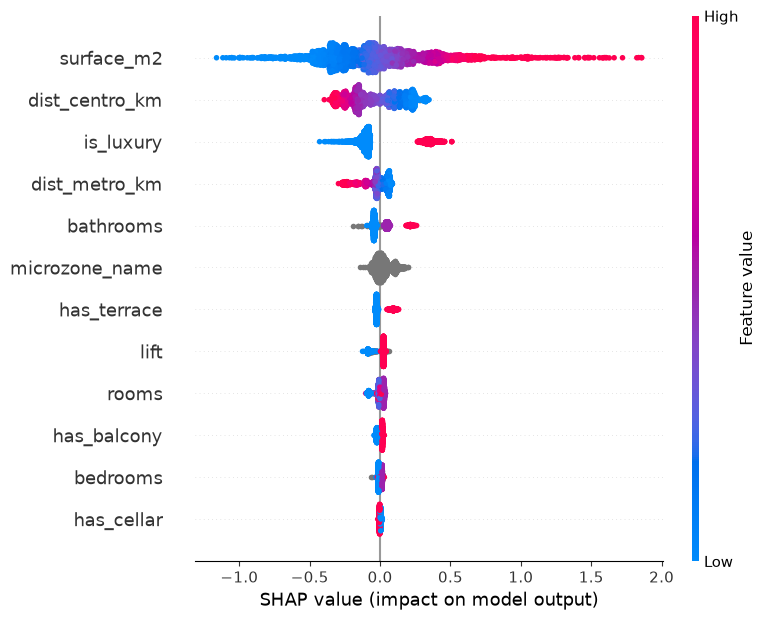

In [56]:
import numpy as np
import shap
import matplotlib.pyplot as plt

# usiamo il modello gia' addestrato (divisione onesta a gruppi) e il suo test set
X_test = Xc.iloc[te]

# CatBoost calcola gli SHAP da solo, in modo nativo
shap_values = modello.get_feature_importance(
    data=__import__("catboost").Pool(X_test, yc[te], cat_features=["microzone_name"]),
    type="ShapValues",
)

# l'ultima colonna e' il valore atteso di base, la togliamo
shap_values = shap_values[:, :-1]

# grafico riassuntivo: quali feature pesano di piu' e in che direzione
shap.summary_plot(shap_values, X_test, feature_names=list(X_test.columns), show=True)

In [57]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

num_feat = ["surface_m2", "rooms", "bathrooms", "bedrooms", "lift",
            "is_luxury", "has_cellar", "has_balcony", "has_terrace",
            "dist_centro_km", "dist_metro_km", "year_built"]      # <-- anno
cat_feat = ["microzone_name", "condition"]                        # <-- stato

Xc = df[num_feat + cat_feat].copy()
Xc["microzone_name"] = Xc["microzone_name"].fillna("Sconosciuta").astype(str)
Xc["condition"] = Xc["condition"].fillna("Sconosciuto").astype(str)
yc = np.log1p(df["price_raw"]).values
gruppi = df["microzone_name"].fillna("Sconosciuta").astype(str)

gkf = GroupKFold(n_splits=5)
r2_folds = []
for i, (tr, te) in enumerate(gkf.split(Xc, yc, groups=gruppi)):
    m = CatBoostRegressor(iterations=600, learning_rate=0.05, depth=6,
                          cat_features=cat_feat, random_seed=42, verbose=0)
    m.fit(Xc.iloc[tr], yc[tr])
    r2 = r2_score(yc[te], m.predict(Xc.iloc[te]))
    r2_folds.append(r2)
    print(f"  fold {i+1}: R2 = {r2:.3f}")
r2_folds = np.array(r2_folds)
print(f"\nCON stato e anno: R2 {r2_folds.mean():.3f} (+/- {r2_folds.std():.3f})")
print(f"SENZA (solo geografia): 0.893 (+/- 0.008)")

  fold 1: R2 = 0.907
  fold 2: R2 = 0.901
  fold 3: R2 = 0.907
  fold 4: R2 = 0.895
  fold 5: R2 = 0.916

CON stato e anno: R2 0.905 (+/- 0.007)
SENZA (solo geografia): 0.893 (+/- 0.008)


In [58]:
import json
import numpy as np
from geopy.distance import geodesic

with open("data/raw/parchi.geojson") as f:
    parchi_geo = json.load(f)

def centroide(coords):
    # scende nella struttura annidata dei MultiPolygon e media tutti i punti
    punti = []
    def scendi(x):
        if isinstance(x, list) and len(x) == 2 and isinstance(x[0], (int, float)):
            punti.append(x)          # [lon, lat]
        elif isinstance(x, list):
            for y in x:
                scendi(y)
    scendi(coords)
    arr = np.array(punti)
    return arr[:, 1].mean(), arr[:, 0].mean()   # (lat, lon), coordinate girate

parchi = []
for feat in parchi_geo["features"]:
    lat, lon = centroide(feat["geometry"]["coordinates"])
    parchi.append((lat, lon))
parchi = np.array(parchi)
print("parchi caricati:", len(parchi))

def dist_parco(lat, lon):
    if np.isnan(lat) or np.isnan(lon):
        return np.nan
    return min(geodesic((lat, lon), (plat, plon)).km for plat, plon in parchi)

parchi caricati: 1065


In [59]:
df["dist_parco_km"] = [dist_parco(la, lo) for la, lo in zip(df["lat"], df["lon"])]
print(df["dist_parco_km"].describe())

count    17267.000000
mean         0.593361
std          0.387918
min          0.003648
25%          0.320056
50%          0.517023
75%          0.772533
max          4.090235
Name: dist_parco_km, dtype: float64


In [60]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

num_feat = ["surface_m2", "rooms", "bathrooms", "bedrooms", "lift",
            "is_luxury", "has_cellar", "has_balcony", "has_terrace",
            "dist_centro_km", "dist_metro_km", "year_built",
            "dist_parco_km"]                                    # <-- la nuova
cat_feat = ["microzone_name", "condition"]

Xc = df[num_feat + cat_feat].copy()
Xc["microzone_name"] = Xc["microzone_name"].fillna("Sconosciuta").astype(str)
Xc["condition"] = Xc["condition"].fillna("Sconosciuto").astype(str)
yc = np.log1p(df["price_raw"]).values
gruppi = df["microzone_name"].fillna("Sconosciuta").astype(str)

gkf = GroupKFold(n_splits=5)
r2_folds = []
for i, (tr, te) in enumerate(gkf.split(Xc, yc, groups=gruppi)):
    m = CatBoostRegressor(iterations=600, learning_rate=0.05, depth=6,
                          cat_features=cat_feat, random_seed=42, verbose=0)
    m.fit(Xc.iloc[tr], yc[tr])
    r2_folds.append(r2_score(yc[te], m.predict(Xc.iloc[te])))
    print(f"  fold {i+1}: R2 = {r2_folds[-1]:.3f}")
r2_folds = np.array(r2_folds)
print(f"\nCON parchi: R2 {r2_folds.mean():.3f} (+/- {r2_folds.std():.3f})")
print(f"SENZA parchi (stato+anno):  0.905 (+/- 0.007)")

  fold 1: R2 = 0.907
  fold 2: R2 = 0.900
  fold 3: R2 = 0.906
  fold 4: R2 = 0.896
  fold 5: R2 = 0.915

CON parchi: R2 0.905 (+/- 0.006)
SENZA parchi (stato+anno):  0.905 (+/- 0.007)


In [62]:
import json
import numpy as np
from scipy.spatial import cKDTree

def carica_punti(path, lat_key, lon_key):
    with open(path) as f:
        geo = json.load(f)
    punti = []
    for feat in geo["features"]:
        p = feat["properties"]
        lat, lon = p.get(lat_key), p.get(lon_key)
        if lat is not None and lon is not None:
            punti.append((float(lat), float(lon)))
    return punti

# i tre file, con i loro nomi di colonna diversi, uniti in un solo insieme
scuole = []
scuole += carica_punti("data/raw/asiliNido.geojson", "LAT_WGS84", "LONG_WGS84")
scuole += carica_punti("data/raw/scuoleInfanzia.geojson", "LAT_Y_4326", "LONG_X_4326")
scuole += carica_punti("data/raw/scuolePrimarie.geojson", "LAT_Y_4326", "LONG_X_4326")
scuole = np.array(scuole)
print("scuole di base totali:", len(scuole))

# KDTree: trova il piu' vicino tra migliaia in un lampo
albero = cKDTree(scuole)

def distanze_veloci(lat_arr, lon_arr, tree):
    # calcola per tutti gli annunci in una volta
    punti = np.column_stack([lat_arr, lon_arr])
    dist_gradi, _ = tree.query(punti)          # distanza in gradi
    return dist_gradi * 111.0                    # gradi -> km (approssimazione urbana)

mask = df["lat"].notna() & df["lon"].notna()
df["dist_scuola_km"] = np.nan
df.loc[mask, "dist_scuola_km"] = distanze_veloci(
    df.loc[mask, "lat"].values, df.loc[mask, "lon"].values, albero
)
print(df["dist_scuola_km"].describe())

scuole di base totali: 7237
count    17267.000000
mean         0.258460
std          0.168985
min          0.001615
25%          0.151326
50%          0.231049
75%          0.332433
max          2.868104
Name: dist_scuola_km, dtype: float64


In [63]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

num_feat = ["surface_m2", "rooms", "bathrooms", "bedrooms", "lift",
            "is_luxury", "has_cellar", "has_balcony", "has_terrace",
            "dist_centro_km", "dist_metro_km", "year_built",
            "dist_scuola_km"]                                   # scuole sì, parchi no
cat_feat = ["microzone_name", "condition"]

Xc = df[num_feat + cat_feat].copy()
Xc["microzone_name"] = Xc["microzone_name"].fillna("Sconosciuta").astype(str)
Xc["condition"] = Xc["condition"].fillna("Sconosciuto").astype(str)
yc = np.log1p(df["price_raw"]).values
gruppi = df["microzone_name"].fillna("Sconosciuta").astype(str)

gkf = GroupKFold(n_splits=5)
r2_folds = []
for i, (tr, te) in enumerate(gkf.split(Xc, yc, groups=gruppi)):
    m = CatBoostRegressor(iterations=600, learning_rate=0.05, depth=6,
                          cat_features=cat_feat, random_seed=42, verbose=0)
    m.fit(Xc.iloc[tr], yc[tr])
    r2_folds.append(r2_score(yc[te], m.predict(Xc.iloc[te])))
    print(f"  fold {i+1}: R2 = {r2_folds[-1]:.3f}")
r2_folds = np.array(r2_folds)
print(f"\nCON scuole: R2 {r2_folds.mean():.3f} (+/- {r2_folds.std():.3f})")
print(f"SENZA (stato+anno):  0.905 (+/- 0.007)")

  fold 1: R2 = 0.906
  fold 2: R2 = 0.904
  fold 3: R2 = 0.910
  fold 4: R2 = 0.897
  fold 5: R2 = 0.919

CON scuole: R2 0.907 (+/- 0.008)
SENZA (stato+anno):  0.905 (+/- 0.007)


In [65]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

num_feat = ["surface_m2", "rooms", "bathrooms", "bedrooms", "lift",
            "is_luxury", "has_cellar", "has_balcony", "has_terrace",
            "dist_centro_km", "dist_metro_km", "year_built", "dist_scuola_km"]
cat_feat = ["microzone_name", "condition"]

Xc = df[num_feat + cat_feat].copy()
Xc["microzone_name"] = Xc["microzone_name"].fillna("Sconosciuta").astype(str)
Xc["condition"] = Xc["condition"].fillna("Sconosciuto").astype(str)
yc = np.log1p(df["price_raw"]).values
gruppi = df["microzone_name"].fillna("Sconosciuta").astype(str)

# generiamo 20 combinazioni casuali di iperparametri
rng = np.random.default_rng(42)
combinazioni = []
for _ in range(20):
    combinazioni.append({
        "depth": int(rng.integers(4, 9)),
        "learning_rate": round(float(rng.uniform(0.02, 0.15)), 3),
        "iterations": int(rng.integers(400, 1000)),
        "l2_leaf_reg": round(float(rng.uniform(1, 10)), 2),
        "subsample": round(float(rng.uniform(0.7, 1.0)), 2),
    })

def valuta(params, n_splits=3):
    gkf = GroupKFold(n_splits=n_splits)
    r2s = []
    for tr, te in gkf.split(Xc, yc, groups=gruppi):
        m = CatBoostRegressor(cat_features=cat_feat, random_seed=42,
                              verbose=0, **params)
        m.fit(Xc.iloc[tr], yc[tr])
        r2s.append(r2_score(yc[te], m.predict(Xc.iloc[te])))
    return np.mean(r2s)

migliore, miglior_r2 = None, -np.inf
for i, params in enumerate(combinazioni):
    score = valuta(params)
    marcatore = ""
    if score > miglior_r2:
        miglior_r2, migliore = score, params
        marcatore = "  <-- nuovo migliore"
    print(f"[{i+1:2}/20] R2={score:.4f}{marcatore}")

print("\nMIGLIORI PARAMETRI:", migliore)
print(f"miglior R2 (3 fold): {miglior_r2:.4f}")
print("modello attuale (5 fold) era: 0.907")

[ 1/20] R2=0.9079  <-- nuovo migliore
[ 2/20] R2=0.9067
[ 3/20] R2=0.9064
[ 4/20] R2=0.9027
[ 5/20] R2=0.9090  <-- nuovo migliore
[ 6/20] R2=0.9096  <-- nuovo migliore
[ 7/20] R2=0.9084
[ 8/20] R2=0.9058
[ 9/20] R2=0.9087
[10/20] R2=0.9072
[11/20] R2=0.9003
[12/20] R2=0.9002
[13/20] R2=0.9094
[14/20] R2=0.9015
[15/20] R2=0.9042
[16/20] R2=0.9048
[17/20] R2=0.9057
[18/20] R2=0.9071
[19/20] R2=0.9051
[20/20] R2=0.9018

MIGLIORI PARAMETRI: {'depth': 4, 'learning_rate': 0.066, 'iterations': 854, 'l2_leaf_reg': 9.74, 'subsample': 0.97}
miglior R2 (3 fold): 0.9096
modello attuale (5 fold) era: 0.907


In [66]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

best = {'depth': 4, 'learning_rate': 0.066, 'iterations': 854,
        'l2_leaf_reg': 9.74, 'subsample': 0.97}

gkf = GroupKFold(n_splits=5)
r2_folds = []
for i, (tr, te) in enumerate(gkf.split(Xc, yc, groups=gruppi)):
    m = CatBoostRegressor(cat_features=cat_feat, random_seed=42, verbose=0, **best)
    m.fit(Xc.iloc[tr], yc[tr])
    r2_folds.append(r2_score(yc[te], m.predict(Xc.iloc[te])))
    print(f"  fold {i+1}: R2 = {r2_folds[-1]:.4f}")
r2_folds = np.array(r2_folds)
print(f"\nCON tuning (5 fold): R2 {r2_folds.mean():.4f} (+/- {r2_folds.std():.4f})")
print(f"SENZA tuning era:    R2 0.907  (+/- 0.008)")

  fold 1: R2 = 0.9057
  fold 2: R2 = 0.9060
  fold 3: R2 = 0.9077
  fold 4: R2 = 0.8951
  fold 5: R2 = 0.9138

CON tuning (5 fold): R2 0.9057 (+/- 0.0060)
SENZA tuning era:    R2 0.907  (+/- 0.008)


In [67]:
import numpy as np
from catboost import CatBoostRegressor

best = {'depth': 4, 'learning_rate': 0.066, 'iterations': 854,
        'l2_leaf_reg': 9.74, 'subsample': 0.97}

# modello finale: addestrato su TUTTI i dati puliti
modello_finale = CatBoostRegressor(cat_features=cat_feat, random_seed=42,
                                   verbose=0, **best)
modello_finale.fit(Xc, yc)

# salviamo su disco: cosi' non devi riaddestrarlo ogni volta
modello_finale.save_model("data/processed/modello_prezzi_milano.cbm")
print("modello salvato")

modello salvato


In [68]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold

# previsioni fuori campione: ogni casa predetta da un modello che non l'ha vista
pred_oof = np.zeros(len(yc))
gkf = GroupKFold(n_splits=5)
for tr, te in gkf.split(Xc, yc, groups=gruppi):
    m = CatBoostRegressor(cat_features=cat_feat, random_seed=42, verbose=0, **best)
    m.fit(Xc.iloc[tr], yc[tr])
    pred_oof[te] = m.predict(Xc.iloc[te])

# riportiamo tutto in euro e calcoliamo i residui
df_res = df.copy()
df_res["prezzo_predetto"] = np.expm1(pred_oof)
df_res["prezzo_reale"] = np.expm1(yc)
df_res["residuo_euro"] = df_res["prezzo_reale"] - df_res["prezzo_predetto"]
# residuo percentuale: quanto il prezzo reale si discosta dalla stima, in %
df_res["residuo_pct"] = (df_res["residuo_euro"] / df_res["prezzo_predetto"]) * 100

print(df_res["residuo_pct"].describe())

count    17407.000000
mean         0.730937
std         21.031662
min        -89.146667
25%        -13.121348
50%         -0.139123
75%         13.301967
max        331.683781
Name: residuo_pct, dtype: float64


In [69]:
sottovalutati = df_res.nsmallest(15, "residuo_pct")[
    ["prezzo_reale", "prezzo_predetto", "residuo_pct",
     "surface_m2", "microzone_name", "condition", "year_built"]
]
print("--- I 15 immobili piu' SOTTOVALUTATI secondo il modello ---")
print(sottovalutati.to_string())

--- I 15 immobili piu' SOTTOVALUTATI secondo il modello ---
       prezzo_reale  prezzo_predetto  residuo_pct  surface_m2                 microzone_name               condition  year_built
15973       10000.0     9.213759e+04   -89.146667         5.0               Quartiere Feltre       Buono / Abitabile         NaN
18815       20250.0     1.079566e+05   -81.242468        16.0                       Precotto                     NaN         NaN
17168       20250.0     1.057072e+05   -80.843318        17.0                       Precotto       Buono / Abitabile         NaN
7981       599000.0     2.964406e+06   -79.793592       580.0  Porta Romana - Medaglie d'Oro       Buono / Abitabile      1900.0
16768      105000.0     3.815178e+05   -72.478350       100.0                Scala - Manzoni                     NaN         NaN
13793      285000.0     1.013772e+06   -71.887167       190.0                       Centrale  Nuovo / In costruzione      2026.0
16330      195000.0     6.905192e+05 

In [ ]:
sopravvalutati = df_res.nlargest(15, "residuo_pct")[
    ["prezzo_reale", "prezzo_predetto", "residuo_pct",
     "surface_m2", "microzone_name", "condition", "year_built"]
]
print("--- I 15 immobili piu' SOPRAVVALUTATI secondo il modello ---")
print(sopravvalutati.to_string())

In [ ]:
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", None)   # non troncare gli URL

# --- STADIO 1: filtro di affidabilita' ---
prezzo_mq = df_res["prezzo_reale"] / df_res["surface_m2"]
affidabile = (
    (df_res["surface_m2"] >= 30) &
    (df_res["surface_m2"] <= 400) &
    (prezzo_mq >= 1500) &
    (prezzo_mq <= 20000) &
    (df_res["is_project"] == 0)
)
fascia_pulita = df_res[affidabile].copy()
print(f"immobili nella fascia affidabile: {len(fascia_pulita)} su {len(df_res)}")

# --- STADIO 2: affari plausibili, sottovalutati ma non estremi ---
affari = fascia_pulita[
    (fascia_pulita["residuo_pct"] <= -20) &
    (fascia_pulita["residuo_pct"] >= -40)
].sort_values("residuo_pct").copy()

# --- URL verificabile dall'id ---
affari["url"] = "https://www.immobiliare.it/annunci/" + affari["id"].astype(int).astype(str) + "/"

print(f"potenziali affari trovati: {len(affari)}\n")

colonne = ["prezzo_reale", "prezzo_predetto", "residuo_pct",
           "surface_m2", "microzone_name", "condition", "url"]
print(affari[colonne].head(20).to_string(index=False))

In [ ]:
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda x: f"{x:,.0f}")   # niente notazione scientifica

prezzo_mq = df_res["prezzo_reale"] / df_res["surface_m2"]
affidabile = (
    (df_res["surface_m2"] >= 30) &
    (df_res["surface_m2"] <= 400) &
    (prezzo_mq >= 1500) &
    (prezzo_mq <= 20000) &
    (df_res["is_project"] == 0)
)
fascia_pulita = df_res[affidabile].copy()
print(f"immobili nella fascia affidabile: {len(fascia_pulita)} su {len(df_res)}")

affari = fascia_pulita[
    (fascia_pulita["residuo_pct"] <= -20) &
    (fascia_pulita["residuo_pct"] >= -40)
].sort_values("residuo_pct").copy()

# arrotondiamo per la leggibilita'
affari["prezzo_reale"] = affari["prezzo_reale"].round(0)
affari["prezzo_predetto"] = affari["prezzo_predetto"].round(0)
affari["residuo_pct"] = affari["residuo_pct"].round(1)
affari["url"] = "https://www.immobiliare.it/annunci/" + affari["id"].astype(int).astype(str) + "/"

print(f"potenziali affari trovati: {len(affari)}\n")

colonne = ["prezzo_reale", "prezzo_predetto", "residuo_pct",
           "surface_m2", "microzone_name", "condition", "url"]
print(affari[colonne].head(20).to_string(index=False))

In [ ]:
from IPython.display import HTML

tabella = affari[["prezzo_reale", "prezzo_predetto", "residuo_pct",
                  "surface_m2", "microzone_name", "condition", "id"]].head(20).copy()
tabella["link"] = tabella["id"].astype(int).apply(
    lambda x: f'<a href="https://www.immobiliare.it/annunci/{x}/" target="_blank">apri</a>'
)
HTML(tabella.to_html(escape=False, index=False))

In [ ]:
from IPython.display import HTML

tabella = affari[["prezzo_reale", "prezzo_predetto", "residuo_pct",
                  "surface_m2", "microzone_name", "condition", "id"]].head(20).copy()
tabella["link"] = tabella["id"].astype(int).apply(
    lambda x: f'<a href="https://www.immobiliare.it/annunci/{x}/" target="_blank">apri</a>'
)
HTML(tabella.to_html(escape=False, index=False))

In [ ]:
import numpy as np

# --- ripartiamo dalla fascia affidabile gia' filtrata ---
prezzo_mq = df_res["prezzo_reale"] / df_res["surface_m2"]
affidabile = (
    (df_res["surface_m2"] >= 30) & (df_res["surface_m2"] <= 400) &
    (prezzo_mq >= 1500) & (prezzo_mq <= 20000) &
    (df_res["is_project"] == 0)
)
fascia = df_res[affidabile].copy()

# --- STADIO A: correzione del bias di zona ---
# il residuo medio di ogni microzona misura quanto il modello la sbaglia in modo sistematico
bias_zona = fascia.groupby("microzone_name")["residuo_pct"].transform("mean")
# il residuo "corretto" e' lo scarto rispetto alla media della SUA zona:
# cosi' un immobile e' un affare solo se costa meno degli altri della stessa zona,
# non perche' il modello sbaglia tutta la zona
fascia["residuo_corretto"] = fascia["residuo_pct"] - bias_zona

# --- STADIO B: solo immobili in ottimo stato, dove lo sconto non nasconde lavori ---
solo_buoni = fascia[fascia["condition"].isin(["Ottimo / Ristrutturato", "Nuovo / In costruzione"])]
# escludiamo pero' le nuove costruzioni, che abbiamo visto essere spesso ingannevoli
solo_buoni = solo_buoni[solo_buoni["condition"] == "Ottimo / Ristrutturato"]

# --- STADIO C: finestra selettiva sul residuo CORRETTO ---
affari = solo_buoni[
    (solo_buoni["residuo_corretto"] <= -25) &
    (solo_buoni["residuo_corretto"] >= -45)
].sort_values("residuo_corretto").copy()

affari["url"] = "https://www.immobiliare.it/annunci/" + affari["id"].astype(int).astype(str) + "/"
affari["prezzo_reale"] = affari["prezzo_reale"].round(0)
affari["prezzo_predetto"] = affari["prezzo_predetto"].round(0)
affari["residuo_corretto"] = affari["residuo_corretto"].round(1)

print(f"affari selezionati: {len(affari)}\n")
colonne = ["prezzo_reale", "prezzo_predetto", "residuo_corretto",
           "surface_m2", "microzone_name", "condition", "url"]
print(affari[colonne].head(20).to_string(index=False))

In [ ]:
import numpy as np

prezzo_mq = df_res["prezzo_reale"] / df_res["surface_m2"]
affidabile = (
    (df_res["surface_m2"] >= 40) & (df_res["surface_m2"] <= 150) &   # <-- fascia solida
    (prezzo_mq >= 1500) & (prezzo_mq <= 20000) &
    (df_res["is_project"] == 0)
)
fascia = df_res[affidabile].copy()

bias_zona = fascia.groupby("microzone_name")["residuo_pct"].transform("mean")
fascia["residuo_corretto"] = fascia["residuo_pct"] - bias_zona

solo_buoni = fascia[fascia["condition"] == "Ottimo / Ristrutturato"].copy()

# finestra piu' severa: almeno -35% corretto
affari = solo_buoni[solo_buoni["residuo_corretto"] <= -35].sort_values("residuo_corretto").copy()

affari["url"] = "https://www.immobiliare.it/annunci/" + affari["id"].astype(int).astype(str) + "/"
for c in ["prezzo_reale", "prezzo_predetto"]:
    affari[c] = affari[c].round(0)
affari["residuo_corretto"] = affari["residuo_corretto"].round(1)

print(f"affari selezionati: {len(affari)}\n")
colonne = ["prezzo_reale", "prezzo_predetto", "residuo_corretto",
           "surface_m2", "microzone_name", "condition", "url"]
print(affari[colonne].head(20).to_string(index=False))

In [77]:
print(df["floor_raw"].value_counts(dropna=False).head(40))

floor_raw
1          3333
2          2504
3          2016
T          2008
4          1692
R          1366
5          1148
6           710
7           448
S           344
NaN         327
8           264
S, 1        107
9            83
S, 2         79
S, R         71
T, 1         70
S, 3         67
S, 4         51
S, 5         39
S, T         34
10           34
11           31
4 - 5        29
S - T        25
2 - 3        24
12           24
S, 6         23
5 - 6        21
T, 3         19
1 - 2        19
3 - 4        18
T, R         16
S, 7         16
S, T, 1      15
13           14
8 - 9        13
T, 6         13
14           12
S, 8         11
Name: count, dtype: int64


In [78]:
import numpy as np
import pandas as pd

def normalizza_piano(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return np.nan
    s = str(v).strip().upper()

    # mappa delle etichette speciali a valori ordinati
    speciali = {"S": -1, "T": 0, "R": 0.5}

    # immobili su piu' livelli: separatori virgola o trattino -> prendi il piu' basso
    parti = [p.strip() for p in s.replace("-", ",").split(",")]

    valori = []
    for p in parti:
        if p in speciali:
            valori.append(speciali[p])
        elif p.isdigit():
            valori.append(int(p))
        # ignora frammenti non riconosciuti
    if not valori:
        return np.nan
    return min(valori)   # il piano piu' basso occupato

In [79]:
for test in ["1", "T", "R", "S", "S, 1", "T, 3", "S, T, 1", "4 - 5", "12", None]:
    print(f"{str(test):10} -> {normalizza_piano(test)}")

1          -> 1
T          -> 0
R          -> 0.5
S          -> -1
S, 1       -> -1
T, 3       -> 0
S, T, 1    -> -1
4 - 5      -> 4
12         -> 12
None       -> nan


In [80]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

# aggiungi il piano normalizzato al dataframe
df["floor_num"] = df["floor_raw"].apply(normalizza_piano)
print("piano normalizzato, mancanti:", df["floor_num"].isna().sum())

best = {'depth': 4, 'learning_rate': 0.066, 'iterations': 854,
        'l2_leaf_reg': 9.74, 'subsample': 0.97}

num_feat = ["surface_m2", "rooms", "bathrooms", "bedrooms", "lift",
            "is_luxury", "has_cellar", "has_balcony", "has_terrace",
            "dist_centro_km", "dist_metro_km", "year_built", "dist_scuola_km",
            "floor_num"]                                          # <-- il piano
cat_feat = ["microzone_name", "condition"]

Xc = df[num_feat + cat_feat].copy()
Xc["microzone_name"] = Xc["microzone_name"].fillna("Sconosciuta").astype(str)
Xc["condition"] = Xc["condition"].fillna("Sconosciuto").astype(str)
yc = np.log1p(df["price_raw"]).values
gruppi = df["microzone_name"].fillna("Sconosciuta").astype(str)

gkf = GroupKFold(n_splits=5)
r2_folds = []
for i, (tr, te) in enumerate(gkf.split(Xc, yc, groups=gruppi)):
    m = CatBoostRegressor(cat_features=cat_feat, random_seed=42, verbose=0, **best)
    m.fit(Xc.iloc[tr], yc[tr])
    r2_folds.append(r2_score(yc[te], m.predict(Xc.iloc[te])))
    print(f"  fold {i+1}: R2 = {r2_folds[-1]:.4f}")
r2_folds = np.array(r2_folds)
print(f"\nCON piano: R2 {r2_folds.mean():.4f} (+/- {r2_folds.std():.4f})")
print(f"SENZA piano era: 0.906")

piano normalizzato, mancanti: 329
  fold 1: R2 = 0.9096
  fold 2: R2 = 0.9110
  fold 3: R2 = 0.9108
  fold 4: R2 = 0.9018
  fold 5: R2 = 0.9204

CON piano: R2 0.9107 (+/- 0.0059)
SENZA piano era: 0.906


In [ ]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold

# residui fuori campione col modello CHE ORA CONOSCE IL PIANO
pred_oof = np.zeros(len(yc))
gkf = GroupKFold(n_splits=5)
for tr, te in gkf.split(Xc, yc, groups=gruppi):
    m = CatBoostRegressor(cat_features=cat_feat, random_seed=42, verbose=0, **best)
    m.fit(Xc.iloc[tr], yc[tr])
    pred_oof[te] = m.predict(Xc.iloc[te])

df_res = df.copy()
df_res["prezzo_predetto"] = np.expm1(pred_oof)
df_res["prezzo_reale"] = np.expm1(yc)
df_res["residuo_pct"] = (df_res["prezzo_reale"] - df_res["prezzo_predetto"]) / df_res["prezzo_predetto"] * 100

# stesso filtro selettivo di prima, piu' il piano visibile per la verifica
prezzo_mq = df_res["prezzo_reale"] / df_res["surface_m2"]
affidabile = (
    (df_res["surface_m2"] >= 40) & (df_res["surface_m2"] <= 150) &
    (prezzo_mq >= 1500) & (prezzo_mq <= 20000) &
    (df_res["is_project"] == 0)
)
fascia = df_res[affidabile].copy()
bias_zona = fascia.groupby("microzone_name")["residuo_pct"].transform("mean")
fascia["residuo_corretto"] = fascia["residuo_pct"] - bias_zona
solo_buoni = fascia[fascia["condition"] == "Ottimo / Ristrutturato"].copy()
affari = solo_buoni[solo_buoni["residuo_corretto"] <= -35].sort_values("residuo_corretto").copy()

affari["url"] = "https://www.immobiliare.it/annunci/" + affari["id"].astype(int).astype(str) + "/"
for c in ["prezzo_reale", "prezzo_predetto"]:
    affari[c] = affari[c].round(0)
affari["residuo_corretto"] = affari["residuo_corretto"].round(1)

print(f"affari selezionati: {len(affari)}\n")
colonne = ["prezzo_reale", "prezzo_predetto", "residuo_corretto",
           "surface_m2", "floor_num", "microzone_name", "url"]
print(affari[colonne].head(20).to_string(index=False))

In [ ]:
import numpy as np

prezzo_mq = df_res["prezzo_reale"] / df_res["surface_m2"]
affidabile = (
    (df_res["surface_m2"] >= 40) & (df_res["surface_m2"] <= 150) &
    (prezzo_mq >= 1500) & (prezzo_mq <= 20000) &
    (df_res["is_project"] == 0) &
    (df_res["floor_num"] >= 1)                       # <-- niente seminterrati, terra, rialzati
)
fascia = df_res[affidabile].copy()

bias_zona = fascia.groupby("microzone_name")["residuo_pct"].transform("mean")
fascia["residuo_corretto"] = fascia["residuo_pct"] - bias_zona

solo_buoni = fascia[fascia["condition"] == "Ottimo / Ristrutturato"].copy()

affari = solo_buoni[solo_buoni["residuo_corretto"] <= -40].sort_values("residuo_corretto").copy()

affari["url"] = "https://www.immobiliare.it/annunci/" + affari["id"].astype(int).astype(str) + "/"
for c in ["prezzo_reale", "prezzo_predetto"]:
    affari[c] = affari[c].round(0)
affari["residuo_corretto"] = affari["residuo_corretto"].round(1)

print(f"affari selezionati: {len(affari)}\n")
colonne = ["prezzo_reale", "prezzo_predetto", "residuo_corretto",
           "surface_m2", "floor_num", "microzone_name", "condition", "url"]
print(affari[colonne].to_string(index=False))

In [ ]:
import json

# cerchiamo la nuda proprieta' nel checkpoint grezzo
esempi = []
with open("data/raw/annunci_milano.checkpoint.jsonl") as f:
    for line in f:
        rec = json.loads(line)
        blob = json.dumps(rec, ensure_ascii=False).lower()
        if "nuda propriet" in blob:
            # dove compare? cerchiamo il campo
            titolo = (rec.get("title") or "").lower()
            esempi.append(("nel titolo" if "nuda propriet" in titolo else "altrove", rec.get("id")))
        if len(esempi) >= 10:
            break

print(f"trovati almeno {len(esempi)} annunci con 'nuda proprieta'")
for dove, id_ in esempi:
    print(f"  id {id_}: {dove}")

In [84]:
import json

nuda_ids = []
esempi_testo = []
with open("data/raw/annunci_milano.checkpoint.jsonl") as f:
    for line in f:
        rec = json.loads(line)
        desc = ((rec.get("description") or {}).get("content") or "").lower()
        if "nuda propriet" in desc:
            nuda_ids.append(rec.get("id"))
            if len(esempi_testo) < 5:
                # estraiamo il contesto attorno alla stringa per controllare
                pos = desc.find("nuda propriet")
                esempi_testo.append(desc[max(0, pos-40):pos+60])

print(f"annunci con 'nuda proprieta' nella descrizione: {len(nuda_ids)}\n")
print("--- contesto in 5 esempi, per controllo falsi positivi ---")
for e in esempi_testo:
    print(f"  ...{e}...")

annunci con 'nuda proprieta' nella descrizione: 337

--- contesto in 5 esempi, per controllo falsi positivi ---
  ... premuda 20/a, proponiamo in vendita la nuda proprieta' di un esclusivo appartamento signorile di ci...
  ...nuda proprieta’ (usufruttuario maschio 88 anni)
ampio biloca...
  .... 
proponiamo interessante soluzione in nuda proprietà di 215 mq, unica soluzione al piano, posta al...
  ...rif: bre7 - bilocale nuda proprieta' a due passi da fondazione prada – via breno ...
  ...vendita nuda proprietà
resystems srl propone in vendita la nuda prop...


In [85]:
import pandas as pd
import numpy as np

df = pd.read_parquet("data/processed/annunci_flat.parquet")
print("annunci grezzi:", len(df))

# potatura: le stesse regole di sempre + nuda proprieta'
df = df[df["price_raw"].notna()]
df = df[df["is_auction"] == 0]
df = df[df["is_project"] == 0]
df = df[df["is_nuda_proprieta"] == 0]                    # <-- nuovo
df["prezzo_mq"] = df["price_raw"] / df["surface_m2"]
df = df[df["surface_m2"] <= 1000]
df = df[(df["prezzo_mq"] >= 1000) & (df["prezzo_mq"] <= 20000)]
df.loc[df["bedrooms"] > 8, "bedrooms"] = np.nan
df["floor_num"] = df["floor_raw"].apply(normalizza_piano)
print("annunci dopo pulizia:", len(df))

annunci grezzi: 19207
annunci dopo pulizia: 17086


In [87]:
import json
import numpy as np
from geopy.distance import geodesic
from scipy.spatial import cKDTree

# ---------- 1. distanza dal centro (Duomo) ----------
DUOMO = (45.4637, 9.18813)   # (lat, lon)

def dist_centro(lat, lon):
    if np.isnan(lat) or np.isnan(lon):
        return np.nan
    return geodesic((lat, lon), DUOMO).km

df["dist_centro_km"] = [dist_centro(la, lo) for la, lo in zip(df["lat"], df["lon"])]

# ---------- 2. distanza dalla metro (KDTree, veloce) ----------
with open("data/raw/fermateMetro.geojson") as f:
    metro_geo = json.load(f)
metro = np.array([(feat["geometry"]["coordinates"][1],   # lat
                   feat["geometry"]["coordinates"][0])   # lon
                  for feat in metro_geo["features"]])
albero_metro = cKDTree(metro)

# ---------- 3. distanza dalle scuole di base (tre file uniti, KDTree) ----------
def carica_punti(path, lat_key, lon_key):
    with open(path) as f:
        geo = json.load(f)
    punti = []
    for feat in geo["features"]:
        p = feat["properties"]
        lat, lon = p.get(lat_key), p.get(lon_key)
        if lat is not None and lon is not None:
            punti.append((float(lat), float(lon)))
    return punti

scuole = []
scuole += carica_punti("data/raw/asiliNido.geojson", "LAT_WGS84", "LONG_WGS84")
scuole += carica_punti("data/raw/scuoleInfanzia.geojson", "LAT_Y_4326", "LONG_X_4326")
scuole += carica_punti("data/raw/scuolePrimarie.geojson", "LAT_Y_4326", "LONG_X_4326")
albero_scuole = cKDTree(np.array(scuole))

# ---------- applica metro e scuole in blocco (solo dove ci sono coordinate) ----------
def distanze_kdtree(lat_arr, lon_arr, tree):
    punti = np.column_stack([lat_arr, lon_arr])
    dist_gradi, _ = tree.query(punti)
    return dist_gradi * 111.0   # gradi -> km (approssimazione urbana)

mask = df["lat"].notna() & df["lon"].notna()
df["dist_metro_km"] = np.nan
df["dist_scuola_km"] = np.nan
df.loc[mask, "dist_metro_km"] = distanze_kdtree(
    df.loc[mask, "lat"].values, df.loc[mask, "lon"].values, albero_metro)
df.loc[mask, "dist_scuola_km"] = distanze_kdtree(
    df.loc[mask, "lat"].values, df.loc[mask, "lon"].values, albero_scuole)

print("distanze calcolate")
print(df[["dist_centro_km", "dist_metro_km", "dist_scuola_km"]].describe())

# ---------- salva il dataset pulito e completo ----------
df.to_parquet("data/processed/annunci_clean_full.parquet", index=False)
print("\nsalvato senza nude proprieta':", len(df))

distanze calcolate
       dist_centro_km  dist_metro_km  dist_scuola_km
count          16,947         16,947          16,947
mean                4              1               0
std                 2              1               0
min                 0              0               0
25%                 3              0               0
50%                 4              1               0
75%                 5              1               0
max                11              7               3

salvato senza nude proprieta': 17086


In [88]:
df.to_parquet("data/processed/annunci_clean_full.parquet", index=False)
print("salvato senza nude proprieta':", len(df))

salvato senza nude proprieta': 17086


In [ ]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

df = pd.read_parquet("data/processed/annunci_clean_full.parquet")

best = {'depth': 4, 'learning_rate': 0.066, 'iterations': 854,
        'l2_leaf_reg': 9.74, 'subsample': 0.97}
num_feat = ["surface_m2", "rooms", "bathrooms", "bedrooms", "lift",
            "is_luxury", "has_cellar", "has_balcony", "has_terrace",
            "dist_centro_km", "dist_metro_km", "year_built", "dist_scuola_km",
            "floor_num"]
cat_feat = ["microzone_name", "condition"]

Xc = df[num_feat + cat_feat].copy()
Xc["microzone_name"] = Xc["microzone_name"].fillna("Sconosciuta").astype(str)
Xc["condition"] = Xc["condition"].fillna("Sconosciuto").astype(str)
yc = np.log1p(df["price_raw"]).values
gruppi = df["microzone_name"].fillna("Sconosciuta").astype(str)

# validazione + residui fuori campione in un colpo
gkf = GroupKFold(n_splits=5)
pred_oof = np.zeros(len(yc))
r2_folds = []
for tr, te in gkf.split(Xc, yc, groups=gruppi):
    m = CatBoostRegressor(cat_features=cat_feat, random_seed=42, verbose=0, **best)
    m.fit(Xc.iloc[tr], yc[tr])
    pred_oof[te] = m.predict(Xc.iloc[te])
    r2_folds.append(r2_score(yc[te], pred_oof[te]))
print(f"R2 (senza nude proprieta'): {np.mean(r2_folds):.4f} (+/- {np.std(r2_folds):.4f})")
print("era 0.9107 con le nude proprieta' dentro")

# rigenera i residui e la lista affari
df_res = df.copy()
df_res["prezzo_predetto"] = np.expm1(pred_oof)
df_res["prezzo_reale"] = np.expm1(yc)
df_res["residuo_pct"] = (df_res["prezzo_reale"] - df_res["prezzo_predetto"]) / df_res["prezzo_predetto"] * 100

prezzo_mq = df_res["prezzo_reale"] / df_res["surface_m2"]
affidabile = ((df_res["surface_m2"] >= 40) & (df_res["surface_m2"] <= 150) &
              (prezzo_mq >= 1500) & (prezzo_mq <= 20000) &
              (df_res["is_project"] == 0) & (df_res["floor_num"] >= 1))
fascia = df_res[affidabile].copy()
bias_zona = fascia.groupby("microzone_name")["residuo_pct"].transform("mean")
fascia["residuo_corretto"] = fascia["residuo_pct"] - bias_zona
affari = fascia[(fascia["condition"] == "Ottimo / Ristrutturato") &
                (fascia["residuo_corretto"] <= -40)].sort_values("residuo_corretto").copy()

affari["url"] = "https://www.immobiliare.it/annunci/" + affari["id"].astype(int).astype(str) + "/"
for c in ["prezzo_reale", "prezzo_predetto"]:
    affari[c] = affari[c].round(0)
affari["residuo_corretto"] = affari["residuo_corretto"].round(1)

print(f"\naffari selezionati: {len(affari)}\n")
colonne = ["prezzo_reale", "prezzo_predetto", "residuo_corretto",
           "surface_m2", "floor_num", "microzone_name", "url"]
print(affari[colonne].to_string(index=False))

In [91]:
import json
import numpy as np
from scipy.spatial import cKDTree
from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

# ---------- carica le stazioni ferroviarie ----------
with open("data/raw/stazioni.geojson") as f:   # adatta il nome file
    staz_geo = json.load(f)
stazioni = []
for feat in staz_geo["features"]:
    p = feat["properties"]
    lat, lon = p.get("LAT_Y_4326"), p.get("LONG_X_4326")
    if lat is not None and lon is not None:
        stazioni.append((float(lat), float(lon)))
stazioni = np.array(stazioni)
albero_staz = cKDTree(stazioni)
print("stazioni ferroviarie caricate:", len(stazioni))

# ---------- distanza dalla stazione piu' vicina ----------
mask = df["lat"].notna() & df["lon"].notna()
df["dist_stazione_km"] = np.nan
punti = np.column_stack([df.loc[mask, "lat"].values, df.loc[mask, "lon"].values])
dist_gradi, _ = albero_staz.query(punti)
df.loc[mask, "dist_stazione_km"] = dist_gradi * 111.0
print(df["dist_stazione_km"].describe())

# ---------- rivalida il modello con la nuova feature ----------
best = {'depth': 4, 'learning_rate': 0.066, 'iterations': 854,
        'l2_leaf_reg': 9.74, 'subsample': 0.97}
num_feat = ["surface_m2", "rooms", "bathrooms", "bedrooms", "lift",
            "is_luxury", "has_cellar", "has_balcony", "has_terrace",
            "dist_centro_km", "dist_metro_km", "year_built", "dist_scuola_km",
            "floor_num", "dist_stazione_km"]                      # <-- la nuova
cat_feat = ["microzone_name", "condition"]

Xc = df[num_feat + cat_feat].copy()
Xc["microzone_name"] = Xc["microzone_name"].fillna("Sconosciuta").astype(str)
Xc["condition"] = Xc["condition"].fillna("Sconosciuto").astype(str)
yc = np.log1p(df["price_raw"]).values
gruppi = df["microzone_name"].fillna("Sconosciuta").astype(str)

gkf = GroupKFold(n_splits=5)
r2_folds = []
for i, (tr, te) in enumerate(gkf.split(Xc, yc, groups=gruppi)):
    m = CatBoostRegressor(cat_features=cat_feat, random_seed=42, verbose=0, **best)
    m.fit(Xc.iloc[tr], yc[tr])
    r2_folds.append(r2_score(yc[te], m.predict(Xc.iloc[te])))
    print(f"  fold {i+1}: R2 = {r2_folds[-1]:.4f}")
print(f"\nCON stazioni: R2 {np.mean(r2_folds):.4f} (+/- {np.std(r2_folds):.4f})")
print(f"SENZA stazioni era: 0.9155")

stazioni ferroviarie caricate: 24
count   16,947
mean         1
std          1
min          0
25%          1
50%          1
75%          2
max          9
Name: dist_stazione_km, dtype: float64
  fold 1: R2 = 0.9012
  fold 2: R2 = 0.9232
  fold 3: R2 = 0.9219
  fold 4: R2 = 0.8967
  fold 5: R2 = 0.9178

CON stazioni: R2 0.9122 (+/- 0.0110)
SENZA stazioni era: 0.9155


In [92]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold

# residui fuori campione col modello che conosce le stazioni
pred_oof = np.zeros(len(yc))
gkf = GroupKFold(n_splits=5)
for tr, te in gkf.split(Xc, yc, groups=gruppi):
    m = CatBoostRegressor(cat_features=cat_feat, random_seed=42, verbose=0, **best)
    m.fit(Xc.iloc[tr], yc[tr])
    pred_oof[te] = m.predict(Xc.iloc[te])

dfr = df.copy()
dfr["prezzo_predetto"] = np.expm1(pred_oof)
dfr["prezzo_reale"] = np.expm1(yc)
dfr["residuo_pct"] = (dfr["prezzo_reale"] - dfr["prezzo_predetto"]) / dfr["prezzo_predetto"] * 100

pmq = dfr["prezzo_reale"] / dfr["surface_m2"]
aff = ((dfr["surface_m2"] >= 40) & (dfr["surface_m2"] <= 150) &
       (pmq >= 1500) & (pmq <= 20000) & (dfr["is_project"] == 0) & (dfr["floor_num"] >= 1))
f = dfr[aff].copy()
f["res_corr"] = f["residuo_pct"] - f.groupby("microzone_name")["residuo_pct"].transform("mean")
affari = f[(f["condition"] == "Ottimo / Ristrutturato") & (f["res_corr"] <= -40)].sort_values("res_corr")

print("Turro ancora presente?",
      (affari["microzone_name"] == "Turro").any())
print(affari[["prezzo_reale", "surface_m2", "microzone_name", "dist_stazione_km"]].round(2).to_string(index=False))

Turro ancora presente? True
 prezzo_reale  surface_m2     microzone_name  dist_stazione_km
      170,000         100              Turro                 1
      995,000         127             Turati                 1
      175,000          57            Pasteur                 2
      850,000         118           Palestro                 1
      239,000          79           San Siro                 3
       90,000          48           Muggiano                 8
      848,000         141        Città Studi                 1
      793,000         128 Monte Rosa - Lotto                 1
      204,000          55     Porta Vittoria                 0


In [93]:
import json
from collections import Counter
tipi = Counter()
categorie = Counter()
with open("data/raw/annunci_milano.checkpoint.jsonl") as f:
    for line in f:
        rec = json.loads(line)
        t = (rec.get("topology") or {}).get("typology") or {}
        c = (rec.get("topology") or {}).get("category") or {}
        tipi[t.get("name") if isinstance(t, dict) else t] += 1
        categorie[c.get("name") if isinstance(c, dict) else c] += 1
print("--- typology ---")
for k, v in tipi.most_common(15):
    print(f"  {v:6}  {k}")
print("--- category ---")
for k, v in categorie.most_common(15):
    print(f"  {v:6}  {k}")

--- typology ---
   17315  Appartamento
     670  Attico - Mansarda
     437  Loft
     244  Palazzo - Edificio
     223  Villa
     145  Progetto
      91  Villetta a schiera
      60  Casa indipendente
      17  Rustico - Casale
       5  Palazzo - Stabile
--- category ---
   18818  Residenziale
     244  Palazzi - Edifici
     145  Nuove costruzioni


In [ ]:
import json
tipi_estratti = []
with open("data/raw/annunci_milano.checkpoint.jsonl") as f:
    for i, line in enumerate(f):
        rec = json.loads(line)
        t = (rec.get("topology") or {}).get("typology") or {}
        nome = t.get("name") if isinstance(t, dict) else None
        tipi_estratti.append(nome)
        if i < 5:
            print(f"id {rec.get('id')}: typology = {nome}")
print(f"\ntotale estratti: {len(tipi_estratti)}, di cui vuoti: {tipi_estratti.count(None)}")

In [96]:
import pandas as pd
import numpy as np
import json
from geopy.distance import geodesic
from scipy.spatial import cKDTree

# ---------- carica e pulisci ----------
df = pd.read_parquet("data/processed/annunci_flat.parquet")
print("annunci grezzi:", len(df))

df = df[df["price_raw"].notna()]
df = df[df["is_auction"] == 0]
df = df[df["is_project"] == 0]
df = df[df["is_nuda_proprieta"] == 0]
df["prezzo_mq"] = df["price_raw"] / df["surface_m2"]
df = df[df["surface_m2"] <= 1000]
df = df[(df["prezzo_mq"] >= 1000) & (df["prezzo_mq"] <= 20000)]
df.loc[df["bedrooms"] > 8, "bedrooms"] = np.nan
df["floor_num"] = df["floor_raw"].apply(normalizza_piano)
print("annunci dopo pulizia:", len(df))

# ---------- distanza dal centro (Duomo), geopy ----------
DUOMO = (45.4637, 9.18813)
def dist_centro(lat, lon):
    if np.isnan(lat) or np.isnan(lon):
        return np.nan
    return geodesic((lat, lon), DUOMO).km
df["dist_centro_km"] = [dist_centro(la, lo) for la, lo in zip(df["lat"], df["lon"])]

# ---------- metro e scuole, KDTree ----------
def carica_punti(path, lat_key, lon_key):
    with open(path) as f:
        geo = json.load(f)
    out = []
    for feat in geo["features"]:
        p = feat["properties"]
        la, lo = p.get(lat_key), p.get(lon_key)
        if la is not None and lo is not None:
            out.append((float(la), float(lo)))
    return out

with open("data/raw/fermateMetro.geojson") as f:
    metro_geo = json.load(f)
metro = np.array([(ft["geometry"]["coordinates"][1],
                   ft["geometry"]["coordinates"][0]) for ft in metro_geo["features"]])
albero_metro = cKDTree(metro)

scuole = []
scuole += carica_punti("data/raw/asiliNido.geojson", "LAT_WGS84", "LONG_WGS84")
scuole += carica_punti("data/raw/scuoleInfanzia.geojson", "LAT_Y_4326", "LONG_X_4326")
scuole += carica_punti("data/raw/scuolePrimarie.geojson", "LAT_Y_4326", "LONG_X_4326")
albero_scuole = cKDTree(np.array(scuole))

def dist_kdtree(lat_arr, lon_arr, tree):
    dist_gradi, _ = tree.query(np.column_stack([lat_arr, lon_arr]))
    return dist_gradi * 111.0

mask = df["lat"].notna() & df["lon"].notna()
df["dist_metro_km"] = np.nan
df["dist_scuola_km"] = np.nan
df.loc[mask, "dist_metro_km"] = dist_kdtree(df.loc[mask, "lat"].values,
                                            df.loc[mask, "lon"].values, albero_metro)
df.loc[mask, "dist_scuola_km"] = dist_kdtree(df.loc[mask, "lat"].values,
                                             df.loc[mask, "lon"].values, albero_scuole)
print("distanze calcolate (niente stazioni)")

annunci grezzi: 19207
annunci dopo pulizia: 17086
distanze calcolate (niente stazioni)


In [97]:
df.to_parquet("data/processed/annunci_clean_full.parquet", index=False)
print("salvato:", len(df), "annunci |", df.shape[1], "colonne")

salvato: 17086 annunci | 45 colonne


In [98]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

df = pd.read_parquet("data/processed/annunci_clean_full.parquet")

best = {'depth': 4, 'learning_rate': 0.066, 'iterations': 854,
        'l2_leaf_reg': 9.74, 'subsample': 0.97}

num_feat = ["surface_m2", "rooms", "bathrooms", "bedrooms", "lift",
            "is_luxury", "has_cellar", "has_balcony", "has_terrace",
            "dist_centro_km", "dist_metro_km", "year_built", "dist_scuola_km",
            "floor_num", "double_exposure"]                       # <-- esposizione
cat_feat = ["microzone_name", "condition", "typology", "heating_type"]  # <-- typology, riscaldamento

Xc = df[num_feat + cat_feat].copy()
for c in cat_feat:
    Xc[c] = Xc[c].fillna("Sconosciuto").astype(str)
yc = np.log1p(df["price_raw"]).values
gruppi = df["microzone_name"].fillna("Sconosciuta").astype(str)

gkf = GroupKFold(n_splits=5)
r2_folds = []
for i, (tr, te) in enumerate(gkf.split(Xc, yc, groups=gruppi)):
    m = CatBoostRegressor(cat_features=cat_feat, random_seed=42, verbose=0, **best)
    m.fit(Xc.iloc[tr], yc[tr])
    r2_folds.append(r2_score(yc[te], m.predict(Xc.iloc[te])))
    print(f"  fold {i+1}: R2 = {r2_folds[-1]:.4f}")
print(f"\nCON typology+riscaldamento+esposizione: R2 {np.mean(r2_folds):.4f} (+/- {np.std(r2_folds):.4f})")
print(f"SENZA (solo piano): 0.9155")

  fold 1: R2 = 0.9080
  fold 2: R2 = 0.9287
  fold 3: R2 = 0.9260
  fold 4: R2 = 0.9016
  fold 5: R2 = 0.9187

CON typology+riscaldamento+esposizione: R2 0.9166 (+/- 0.0104)
SENZA (solo piano): 0.9155


In [99]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

def valuta(num_feat, cat_feat, etichetta):
    Xc = df[num_feat + cat_feat].copy()
    for c in cat_feat:
        Xc[c] = Xc[c].fillna("Sconosciuto").astype(str)
    yc = np.log1p(df["price_raw"]).values
    gruppi = df["microzone_name"].fillna("Sconosciuta").astype(str)
    gkf = GroupKFold(n_splits=5)
    r2 = []
    for tr, te in gkf.split(Xc, yc, groups=gruppi):
        m = CatBoostRegressor(cat_features=cat_feat, random_seed=42, verbose=0, **best)
        m.fit(Xc.iloc[tr], yc[tr])
        r2.append(r2_score(yc[te], m.predict(Xc.iloc[te])))
    print(f"{etichetta:35} R2 {np.mean(r2):.4f} (+/- {np.std(r2):.4f})")

base_num = ["surface_m2", "rooms", "bathrooms", "bedrooms", "lift",
            "is_luxury", "has_cellar", "has_balcony", "has_terrace",
            "dist_centro_km", "dist_metro_km", "year_built", "dist_scuola_km", "floor_num"]
base_cat = ["microzone_name", "condition"]

valuta(base_num, base_cat, "base (14 feature)")
valuta(base_num, base_cat + ["typology"], "+ typology")
valuta(base_num, base_cat + ["typology", "heating_type"], "+ typology + riscaldamento")
valuta(base_num + ["double_exposure"], base_cat + ["typology", "heating_type"], "+ tutte e tre")

base (14 feature)                   R2 0.9155 (+/- 0.0119)
+ typology                          R2 0.9143 (+/- 0.0111)
+ typology + riscaldamento          R2 0.9162 (+/- 0.0101)
+ tutte e tre                       R2 0.9166 (+/- 0.0104)


In [ ]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold

df = pd.read_parquet("data/processed/annunci_clean_full.parquet")

best = {'depth': 4, 'learning_rate': 0.066, 'iterations': 854,
        'l2_leaf_reg': 9.74, 'subsample': 0.97}
num_feat = ["surface_m2", "rooms", "bathrooms", "bedrooms", "lift",
            "is_luxury", "has_cellar", "has_balcony", "has_terrace",
            "dist_centro_km", "dist_metro_km", "year_built", "dist_scuola_km",
            "floor_num"]
cat_feat = ["microzone_name", "condition"]

Xc = df[num_feat + cat_feat].copy()
for c in cat_feat:
    Xc[c] = Xc[c].fillna("Sconosciuto").astype(str)
yc = np.log1p(df["price_raw"]).values
gruppi = df["microzone_name"].fillna("Sconosciuta").astype(str)

# residui fuori campione: ogni casa predetta da un modello che non l'ha vista
pred_oof = np.zeros(len(yc))
for tr, te in GroupKFold(n_splits=5).split(Xc, yc, groups=gruppi):
    m = CatBoostRegressor(cat_features=cat_feat, random_seed=42, verbose=0, **best)
    m.fit(Xc.iloc[tr], yc[tr])
    pred_oof[te] = m.predict(Xc.iloc[te])

df["prezzo_predetto"] = np.expm1(pred_oof)
df["residuo_pct"] = (df["price_raw"] - df["prezzo_predetto"]) / df["prezzo_predetto"] * 100


def rileva_occasioni(df, soglia=-40, n=None):
    """
    Rilevatore di occasioni immobiliari.
    Filtra le categorie inaffidabili, corregge il bias di zona, e ordina
    per quanto un immobile e' sottovalutato rispetto ai suoi simili di zona.
    Restituisce candidati da VERIFICARE a mano, non affari certi.
    """
    pmq = df["price_raw"] / df["surface_m2"]
    affidabile = (
        (df["surface_m2"] >= 40) & (df["surface_m2"] <= 150) &   # taglio medio, dove il modello e' solido
        (pmq >= 1500) & (pmq <= 20000) &                          # no falsi milanesi, no super-lusso
        (df["is_project"] == 0) &                                 # no nuove costruzioni
        (df["is_auction"] == 0) &                                 # no aste
        (df["is_nuda_proprieta"] == 0) &                          # no nuda proprieta'
        (df["floor_num"] >= 1) &                                  # no seminterrati/terra/rialzati
        (df["condition"] == "Ottimo / Ristrutturato")             # solo pronti, lo sconto non nasconde lavori
    )
    fascia = df[affidabile].copy()
    # correzione del bias di zona: affare = sotto i simili della STESSA zona
    bias = fascia.groupby("microzone_name")["residuo_pct"].transform("mean")
    fascia["residuo_corretto"] = (fascia["residuo_pct"] - bias).round(1)

    occ = fascia[fascia["residuo_corretto"] <= soglia].sort_values("residuo_corretto")
    occ["url"] = "https://www.immobiliare.it/annunci/" + occ["id"].astype(int).astype(str) + "/"
    for c in ["price_raw", "prezzo_predetto"]:
        occ[c] = occ[c].round(0)
    cols = ["price_raw", "prezzo_predetto", "residuo_corretto",
            "surface_m2", "floor_num", "microzone_name", "url"]
    return occ[cols] if n is None else occ[cols].head(n)


# la lista definitiva
occasioni = rileva_occasioni(df, soglia=-40)
print(f"candidati da verificare: {len(occasioni)}\n")
print(occasioni.to_string(index=False))

In [ ]:
def rileva_occasioni(df, soglia=-35, prezzo_max=700000, n=None):
    pmq = df["price_raw"] / df["surface_m2"]
    affidabile = (
        (df["surface_m2"] >= 40) & (df["surface_m2"] <= 150) &
        (pmq >= 1500) & (pmq <= 20000) &
        (df["price_raw"] <= prezzo_max) &                         # <-- solo mercato di massa
        (df["is_project"] == 0) & (df["is_auction"] == 0) &
        (df["is_nuda_proprieta"] == 0) & (df["floor_num"] >= 1) &
        (df["condition"] == "Ottimo / Ristrutturato")
    )
    fascia = df[affidabile].copy()
    bias = fascia.groupby("microzone_name")["residuo_pct"].transform("mean")
    fascia["residuo_corretto"] = (fascia["residuo_pct"] - bias).round(1)
    occ = fascia[fascia["residuo_corretto"] <= soglia].sort_values("residuo_corretto")
    occ["url"] = "https://www.immobiliare.it/annunci/" + occ["id"].astype(int).astype(str) + "/"
    for c in ["price_raw", "prezzo_predetto"]:
        occ[c] = occ[c].round(0)
    cols = ["price_raw", "prezzo_predetto", "residuo_corretto",
            "surface_m2", "floor_num", "microzone_name", "url"]
    return occ[cols] if n is None else occ[cols].head(n)

occasioni = rileva_occasioni(df, soglia=-35, prezzo_max=700000)
print(f"candidati (mercato di massa, sotto 700k): {len(occasioni)}\n")
print(occasioni.to_string(index=False))

In [102]:
import json
from catboost import CatBoostRegressor

# modello finale addestrato su TUTTI i dati puliti
modello_finale = CatBoostRegressor(cat_features=cat_feat, random_seed=42, verbose=0, **best)
modello_finale.fit(Xc, yc)
modello_finale.save_model("data/processed/modello_prezzi_milano.cbm")

# metadati: cosa serve per riusare il modello
meta = {
    "descrizione": "Modello CatBoost per la stima dei prezzi immobiliari a Milano",
    "target": "log1p(price_raw)",
    "feature_numeriche": num_feat,
    "feature_categoriche": cat_feat,
    "iperparametri": best,
    "n_annunci_addestramento": len(df),
    "r2_validazione_gruppi": 0.9155,
    "errore_mediano_pct": 13,
    "note": "Validato con GroupKFold per microzona. Esclusi: aste, progetti, "
            "nude proprieta', immobili sopra 1000mq, prezzo/mq fuori [1500,20000]."
}
with open("data/processed/modello_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

print("modello salvato:", "data/processed/modello_prezzi_milano.cbm")
print("metadati salvati:", "data/processed/modello_meta.json")
print(f"\nMODELLO DEFINITIVO")
print(f"  feature: {len(num_feat + cat_feat)}")
print(f"  R2 (validazione onesta a gruppi): 0.9155")
print(f"  errore mediano: ~13%")
print(f"  addestrato su: {len(df)} annunci")

modello salvato: data/processed/modello_prezzi_milano.cbm
metadati salvati: data/processed/modello_meta.json

MODELLO DEFINITIVO
  feature: 16
  R2 (validazione onesta a gruppi): 0.9155
  errore mediano: ~13%
  addestrato su: 17086 annunci


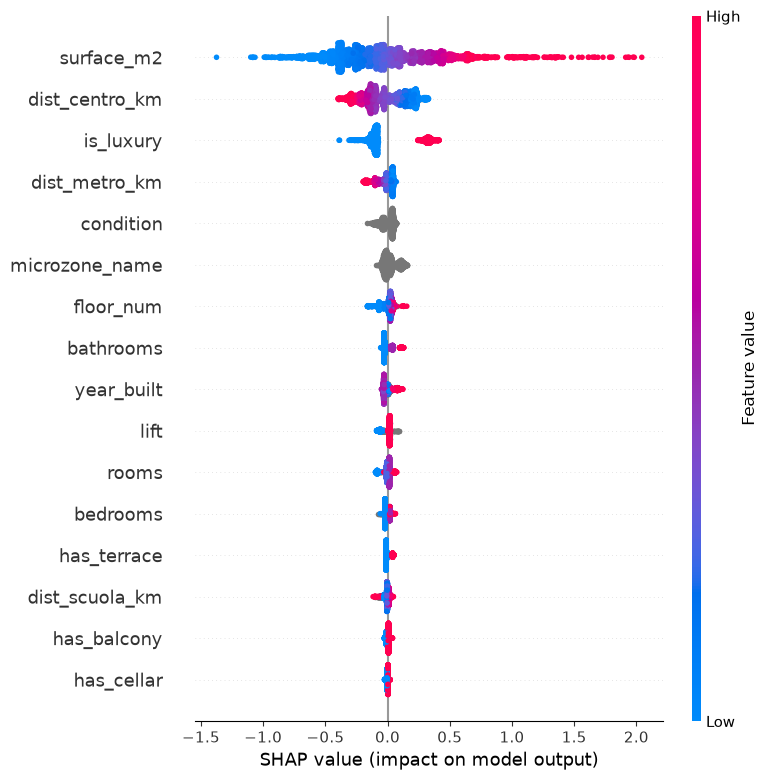

In [103]:
import numpy as np
import shap
from catboost import CatBoostRegressor, Pool
from sklearn.model_selection import GroupShuffleSplit

# addestriamo su una divisione onesta a gruppi e calcoliamo SHAP sul test
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr, te = next(gss.split(Xc, yc, groups=gruppi))

modello_shap = CatBoostRegressor(cat_features=cat_feat, random_seed=42, verbose=0, **best)
modello_shap.fit(Xc.iloc[tr], yc[tr])

# SHAP nativo di CatBoost
X_test = Xc.iloc[te]
shap_values = modello_shap.get_feature_importance(
    data=Pool(X_test, yc[te], cat_features=cat_feat),
    type="ShapValues",
)
shap_values = shap_values[:, :-1]   # l'ultima colonna e' il valore base, si toglie

# grafico riassuntivo
shap.summary_plot(shap_values, X_test, feature_names=list(X_test.columns), show=True)